In [1]:
import numpy as np
import h2py
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy
import pandas
import demes
import demesdraw

mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [14]:
# Load MLE models
mle_models = {}
for rmap in ["bherer", "zhou-JHS"]:
    fnames = []
    lls = []
    for trial in range(30):
        fname = f"fitted_models/main_fit_full_no_sup_{rmap}_try_{rep}.yaml"
        fnames.append(fname)
        g = demes.load(fname)
        lls.append(g.metadata["opt_info"]["ll"])
    fname = fnames[np.argmax(lls)]
    pvals, pnames = h2py.inference.load_params(fname, "full_no_sup_params.yaml")
    mle_models[(rmap)] = (pvals, pnames)
    print(fname, np.max(lls))

fitted_models/main_fit_full_no_sup_bherer_try_0.yaml -598.8652859456207
fitted_models/main_fit_full_no_sup_zhou-JHS_try_0.yaml -600.4767532444591


In [18]:
# Load fitted bootstrap parameters
for rmap in ["bherer", "zhou-JHS"]:
    data = []
    for rep in range(500):
        fname = f"fitted_models/boot_fit_full_no_sup_bherer_rep_{rep}.yaml"
        pvals, pnames = h2py.inference.load_params(fname, "full_no_sup_params.yaml")
        data.append(pvals)
    mle = mle_models[(rmap)][0]
    lower_CI = np.quantile(data, 0.025, axis=0) 
    upper_CI = np.quantile(data, 0.975, axis=0) 
    df = pandas.DataFrame({"name": pnames, "MLE": mle, "CI_lower": lower_CI, "CI_upper": upper_CI})
    df.to_csv(f"bootstrap_{rmap}.csv")

In [20]:
data = pandas.read_csv("bootstrap_bherer.csv")
data = np.array(data)[:, 2:]
lower_CI = np.quantile(data, 0.025, axis=0) 
upper_CI = np.quantile(data, 0.975, axis=0) 
mle, pnames = h2py.inference.load_params("fitted_models/main_fit_full_no_sup_bherer_try_0.yaml", "full_no_sup_params.yaml")
#df1 = pandas.DataFrame({"name": pnames, "MLE": mle, "CI_lower": lower_CI, "CI_upper": upper_CI})

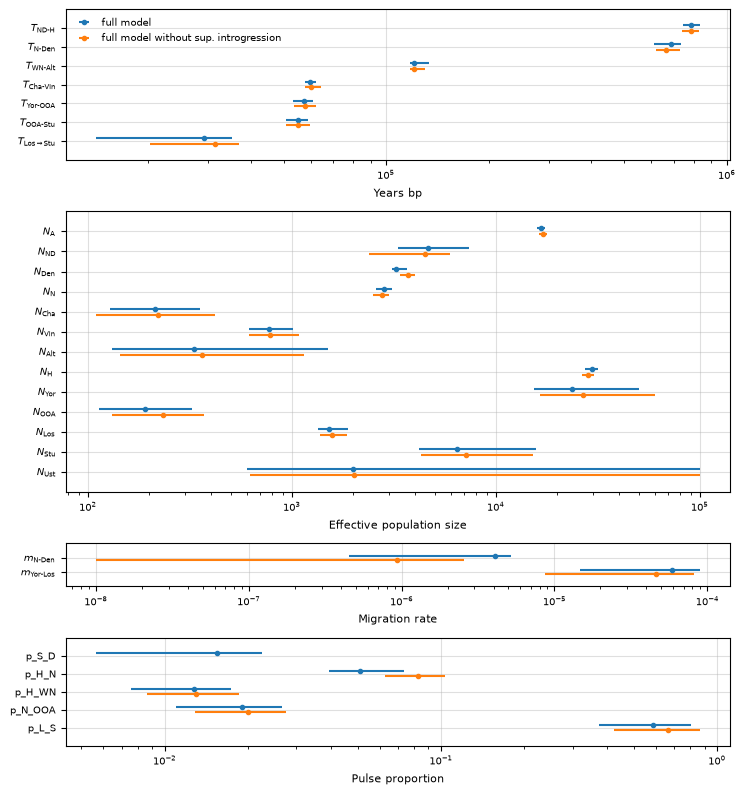

In [4]:
df1 = pandas.read_csv("bootstrap_bherer.csv")
df0 = pandas.read_csv("../mutation_sensitivity/bootstrap_bherer_1.3e-8.csv")
groups = [
    {"params": ['T_NDH', 'T_ND', 'T_AWN', 'T_CV', 'T_OOA', 'T_SL', 'T_L_S'], "log": True},
    {"params": ['N_Anc', 'N_ND', 'N_Den', 'N_N', 'N_Chag', 'N_Vin', 'N_Alt', 'N_MH', 'N_Yor', 'N_OOA', 'N_Los', 'N_Stut', 'N_Ust'],
     "log": True},
    {"params": ["m_ND", "m_LY"], "log": True},
    {"params": ["p_S_D", "p_H_N", "p_H_WN", "p_N_OOA", "p_L_S"], "log": True}
]

x_labels = ["Years bp", "Effective population size", "Migration rate",  "Pulse proportion"]
param_labels = {
    'T_NDH': r'$T_{\text{ND-H}}$',
    'T_ND': r'$T_{\text{N-Den}}$', 
    'T_AWN': r'$T_{\text{WN-Alt}}$', 
    'T_CV': r'$T_{\text{Cha-Vin}}$', 
    'T_OOA': r'$T_{\text{Yor-OOA}}$', 
    'T_SL': r'$T_{\text{OOA-Stu}}$', 
    'T_L_S': r'$T_{\text{Los}\to\text{Stu}}$', 
    'N_Anc': r'$N_{\text{A}}$',
    "N_S": r"$N_{\text{S}}$ (fixed)",
    'N_ND': r'$N_{\text{ND}}$', 
    'N_N': r'$N_{\text{N}}$', 
    'N_MH': r'$N_{\text{H}}$ ', 
    'N_OOA': r'$N_{\text{OOA}}$',
    'N_Alt': r'$N_{\text{Alt}}$', 
    'N_Chag': r'$N_{\text{Cha}}$', 
    'N_Vin': r'$N_{\text{Vin}}$', 
    'N_Den': r'$N_{\text{Den}}$',
    'N_Los': r'$N_{\text{Los}}$',
    'N_Ust': r'$N_{\text{Ust}}$',
    'N_Stut': r'$N_{\text{Stu}}$',
    'N_Yor': r'$N_{\text{Yor}}$', 
    'm_ND': r'$m_{\text{N-Den}}$', 
    'm_LY': r'$m_{\text{Yor-Los}}$', 
    'f_S_D': r'$f_{\text{S} \to \text{D}}$', 
    'f_H_N': r'$f_{\text{H} \to \text{N}}$',
    'f_H_WN': r'$f_{\text{H} \to \text{WN}}$', 
    'f_N_OOA': r'$f_{\text{Vin}\to\text{OOA}}$', 
    'f_L_S': r'$f_{\text{Los}\to\text{Stu}}$',
}

h2py.plotting.plot_param_distributions(
    [df0, df1],
    groups=groups,
    param_labels=param_labels,
    data_labels=["full model", "full model without sup. introgression"],
    figsize=(7.5, 8),
    x_labels=x_labels,
    spread=0.15,
    out="../../figures/no_sup_distrs.pdf"
)